# Data quality check: OpenDota player histories

**Why this notebook exists:** the original plan was to follow individual Dota 2 players
over time (retention and churn from real data). This notebook checks whether OpenDota's
player histories are complete enough for that.

**Result:** they are not. Of 238 sampled players, 76 had no history at all and 119 had
histories that stop before the match they were sampled from; only 43 were complete.
Asking OpenDota to refresh the profiles did not help (0 of 20 improved).

**Decision:** real Dota 2 data is analyzed at match level (notebook 02), and retention,
churn and monetization use a synthetic dataset modeled on Palia (notebook 03).

The player data used here was pseudonymized (salted hash) and is not published.

In [1]:
import pandas as pd

m = pd.read_csv("data/dota_player_matches.csv", parse_dates=["start_time_utc"])

player = m["player_hash"].value_counts().index[0]   # player with the most matches
p = m[m["player_hash"] == player].sort_values("start_time_utc")

print(len(p), "matches, from", p["start_time_utc"].min().date(), "to", p["start_time_utc"].max().date())

4984 matches, from 2025-10-16 to 2026-10-16


<Axes: title={'center': 'Matches per week'}, xlabel='start_time_utc'>

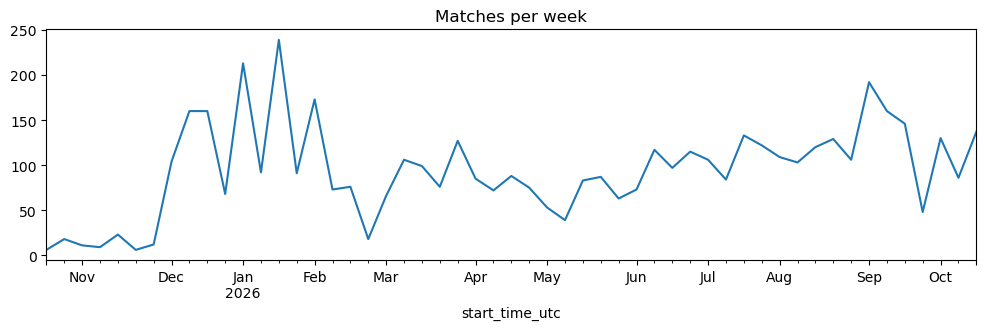

In [3]:
p.set_index("start_time_utc").resample("W").size().plot(figsize=(12, 3), title="Matches per week")

In [5]:
play_days = p["start_time_utc"].dt.normalize().drop_duplicates()
gaps = play_days.diff().dt.days
print("Days played:", len(play_days))
print(gaps.describe())

Days played: 285
count    284.000000
mean       1.285211
std        0.713073
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        5.000000
Name: start_time_utc, dtype: float64


In [6]:
m.isna().mean().round(3)

player_hash       0.000
start_time_utc    0.000
duration_sec      0.000
game_mode         0.000
lobby_type        0.000
hero_id           0.000
win               0.000
kills             0.000
deaths            0.000
assists           0.000
party_size        0.660
average_rank      0.047
leaver_status     0.000
dtype: float64

In [7]:
p9 = pd.read_csv("data/dota_players_m9.csv", parse_dates=["sample_match_time_utc"])
m9 = pd.read_csv("data/dota_player_matches_m9.csv", parse_dates=["start_time_utc"])

# 1. When were these players picked?
print("Pcked from matches played between",
      p9["sample_match_time_utc"].min().date(), "and", p9["sample_match_time_utc"].max().date())

# 2. When did each player play their last match?
last_match = m9.groupby("player_hash")["start_time_utc"].max()
days_since_last = (pd.Timestamp.now(tz="UTC") - last_match).dt.days

print("Players:", len(last_match))
print("Not played in the last 30 days:", (days_since_last > 30).sum(),
      f"({(days_since_last > 30).mean():.0%})")

Pcked from matches played between 2026-01-15 and 2026-01-15
Players: 149
Not played in the last 30 days: 48 (32%)


In [9]:
# Same check for today's group
last_match_now = m.groupby("player_hash")["start_time_utc"].max()
days_since_now = (pd.Timestamp.now(tz="UTC") - last_match_now).dt.days

print("Players:", len(last_match_now))
print("Not played in the last 30 days:", (days_since_now > 30).sum(),
      f"({(days_since_now > 30).mean():.0%})")

Players: 162
Not played in the last 30 days: 50 (31%)


In [10]:
p_now = pd.read_csv("data/dota_players.csv", parse_dates=["sample_match_time_utc"])
last_in_history = m.groupby("player_hash")["start_time_utc"].max()

check = p_now.set_index("player_hash").join(last_in_history.rename("last_in_history"))
check["no_history"] = check["last_in_history"].isna()
check["reaches_pick"] = check["last_in_history"] >= check["sample_match_time_utc"] - pd.Timedelta(hours=2)

print("Players picked:", len(check))
print("No history at all:", check["no_history"].sum())
print("History reaches the match they were picked from:", check["reaches_pick"].sum())
print("History stops before that match:", (~check["no_history"] & ~check["reaches_pick"]).sum())

Players picked: 238
No history at all: 76
History reaches the match they were picked from: 43
History stops before that match: 119


In [11]:
stops = check[~check["no_history"] & ~check["reaches_pick"]].copy()
stops["days_missing"] = (stops["sample_match_time_utc"] - stops["last_in_history"]).dt.days

print("Players whose history stops early:", len(stops))
print(pd.cut(stops["days_missing"],
            bins=[-1, 3, 7, 30, 90, 400],
            labels=["0-3 days", "4-7 days", "8-30 days", "31-90 days", "90+ days"]).value_counts().sort_index())

Players whose history stops early: 119
days_missing
0-3 days      32
4-7 days      17
8-30 days     21
31-90 days    21
90+ days      28
Name: count, dtype: int64
